# Titanic dataset analysis

The aim of this project is to analyse the [Kaggle Titanic dataset](https://www.kaggle.com/c/titanic/data "Kaggle training dataset"), which includes the following steps: 

1. Defining the list of questions to be answered with data analysis.
2. Data wrangling (including its cleansing and adding additional fields) to allow for more convenient consumption of the data and making analysis possible.
3. Data exploration and effective communication of the exploratory steps.
4. Summarising conclusions.

### 1. Defining the list of questions to be answered with data analysis

1. What was the distribution of age across the passengers? Was it different between men and women?
2. What was the distribution of ticket fares? What were the average and the most expensive tickets? How much would this average and the most expensive tickets worth now?
3. How many passengers embarked in different ports? Can we detect the port where the richest passengers embarked? How much would the median price for this subset of passengers worth now?
4. How many passengers by gender were there on the ship? What was the survival rate for men, women and children? Was sex correlated to the survival rate? 
5. What was the distribution of passengers among different classes? What was the survival rate among different ticket classes? Was ticket class correlated to the survival rate? 

In [175]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys

data1 = pd.read_csv("titanic-data.csv")

## DATA CLEANING


In [176]:
data1.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [177]:
data1.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Looking at the details of the data, we can say that the data types used for the various columns are ok.
We can also see that the minimum age is 0.42 which means we have infants and ther could be missing informations or null values
The minimum fare is 0.0, which means that some people went in for free.

In [178]:
totalnum = data1["PassengerId"].count()

In [179]:
data1.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [180]:

print("The total number of people on the titanic: ",totalnum)
print(f"Age: {data1["Age"].isna().sum()} null cells")
print(f"Cabin:  {data1["Cabin"].isna().sum()} null cells")
print(f"Embarked:  {data1["Embarked"].isna().sum()} null cells")
print("\nSo wee will have to manipulate the data to fill the null, but the carbin data is not important")




The total number of people on the titanic:  891
Age: 177 null cells
Cabin:  687 null cells
Embarked:  2 null cells

So wee will have to manipulate the data to fill the null, but the carbin data is not important


In [181]:
data1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [182]:
def rex(datax):
    if datax == "S":
        return "Southampton"
    if datax == "C":
        return "Cherbourg"
    if datax == "Q":
        return "Queenstown"

data1["Embarked"] = data1["Embarked"].apply(rex)
data1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,Cherbourg
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,Southampton
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,Southampton
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,Southampton


In [183]:
data1.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [184]:
def st_con(datax):
    age = datax["Age"]
    sex = datax["Sex"]
    if age < 14:
        return "child"
    else:
        return sex

data1["Age"] = data1.groupby(["Sex","Pclass","Embarked"])["Age"].transform(lambda x:x.fillna(x.median()))
data1["Embarked"] = data1.groupby(["Sex","Pclass"])["Embarked"].transform(lambda x:x.fillna(x.value_counts().index[0]))
data1["Status"] = data1.apply(st_con,axis=1)
data1.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              2
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Status           0
dtype: int64

## 1. What was the distribution of age across the passengers? What is the difference between men and women?

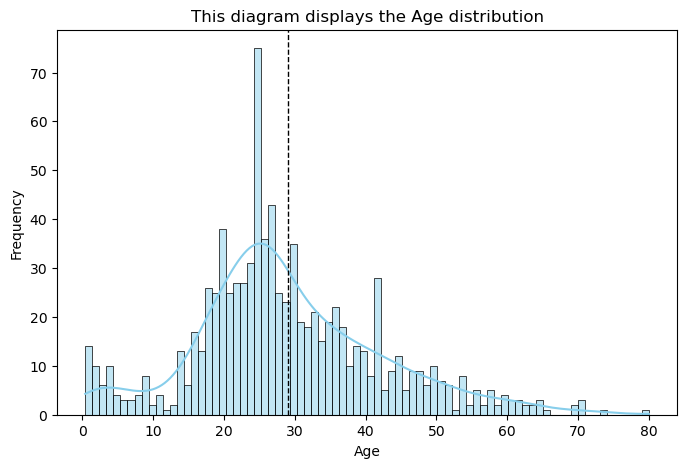

In [185]:
plt.figure(figsize=(8,5))
sns.histplot(data = data1,x="Age",bins=80,kde=True,color="skyblue",edgecolor="black")
plt.axvline(data1["Age"].mean(),color="black",linestyle="dashed",linewidth=1)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("This diagram displays the Age distribution")
plt.show()

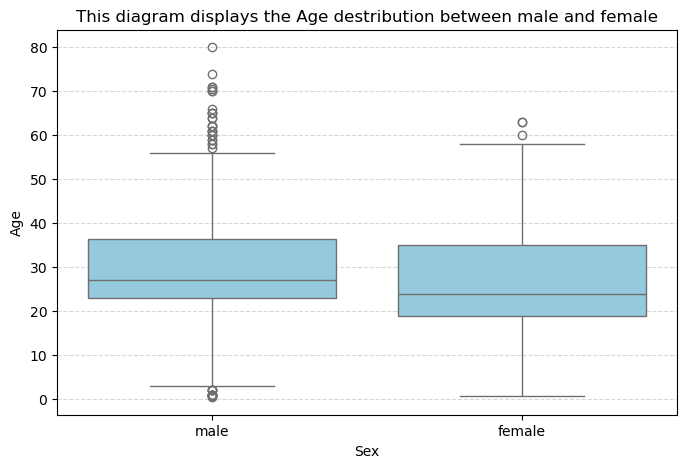

In [186]:
plt.figure(figsize=(8,5))
sns.boxplot(data = data1, x="Sex",y="Age",color="skyblue")
plt.xlabel("Sex")
plt.ylabel("Age")
plt.title("This diagram displays the Age destribution between male and female")
plt.grid(axis="y",linestyle="--",alpha=0.5)
plt.show()

## 2. What was the distribution of ticket fares? What were the average and the most expensive tickets? 
## How much would this average and the most expensive tickets worth now?

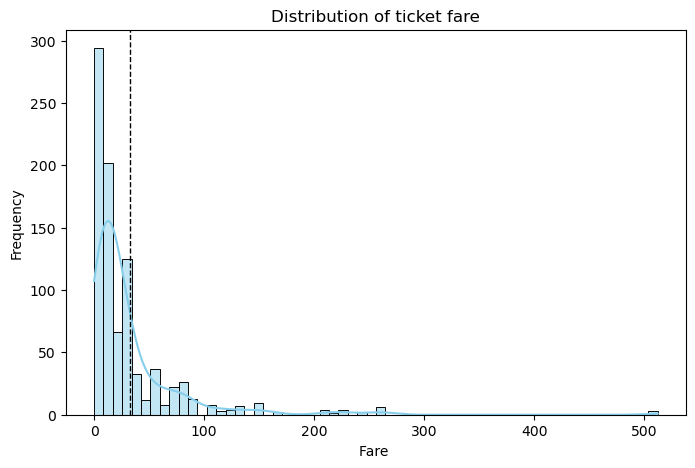

In [187]:
plt.figure(figsize=(8,5))
sns.histplot(data=data1,x="Fare",kde="True",color="skyblue",edgecolor="black")
plt.axvline(data1["Fare"].mean(),color="black",linestyle="--",linewidth=1)
plt.title("Distribution of ticket fare")
plt.xlabel("Fare ")
plt.ylabel("Frequency")
plt.show()

In [188]:
print(f"The average fare is: {data1["Fare"].mean():.2f}")
print(f"The most expensive fare: {data1["Fare"].max():.2f}")

The average fare is: 32.20
The most expensive fare: 512.33


In [189]:
## Worth now

## 3. Can we detect the port where the richest passengers embarked? How much would the median price for this subset of passengers worth now?

In [190]:
data1.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Status'],
      dtype='object')

In [191]:
fare_by_port = data1.groupby("Embarked").agg(
    Mean=("Fare", "mean"),
    Passenger_Count=("PassengerId", "count")
).round(2)

print(fare_by_port)

              Mean  Passenger_Count
Embarked                           
Cherbourg    59.95              168
Queenstown   13.28               77
Southampton  27.24              646


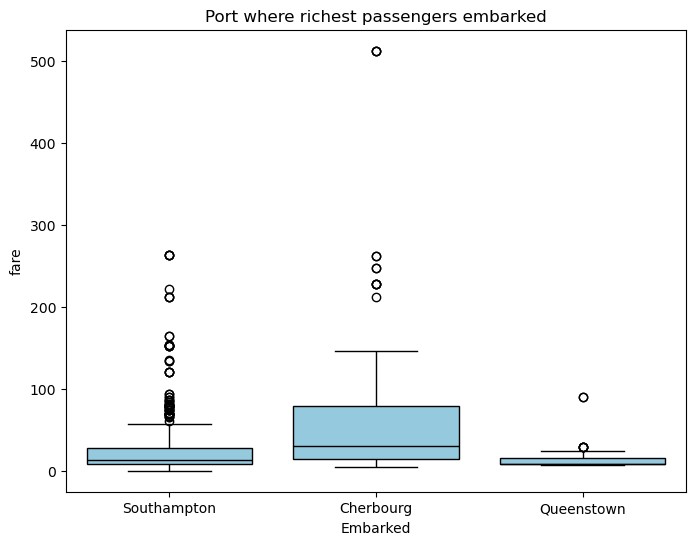

In [192]:
plt.figure(figsize=(8,6))
sns.boxplot(data1,x="Embarked",y="Fare",color="skyblue",linecolor="black")
plt.title("Port where richest passengers embarked")
plt.xlabel("Embarked")
plt.ylabel("fare")
plt.show()

### From the above observations, we can see that see the the port with the richest people is the Cherbourg and the mean of this subset at the port was   59.95.

# 4. What was the survival rate for men, women and children? what sex correlated to survival rate?

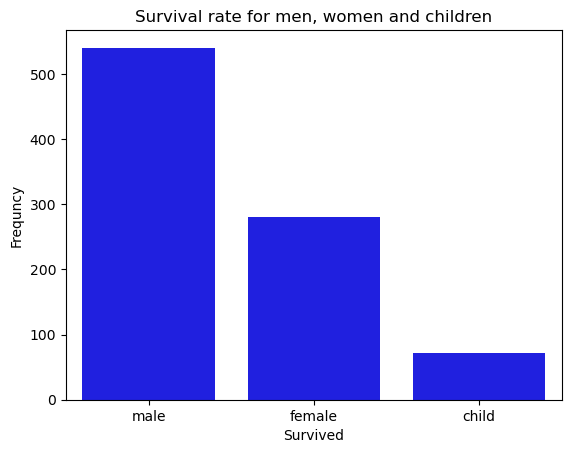

In [193]:
suvivals = data1[(data1["Survived"]==1)]

plt.Figure(figsize=(8,5))
sns.countplot(data=data1,x="Status",color="blue")
plt.title("Survival rate for men, women and children")
plt.xlabel("Survived")
plt.ylabel("Frequncy")
plt.show()

In [194]:
data1.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Status'],
      dtype='object')

In [199]:
suvivals = data1[(data1["Survived"]==1)]
status_summary = pd.DataFrame({
    "Count": data1["Status"].value_counts(),
    "Percentage": (
        data1["Status"].value_counts(normalize=True) * 100
    ).round(2)
})

print(status_summary)

        Count  Percentage
Status                   
male      540       60.61
female    280       31.43
child      71        7.97


### From the look of things men have the largest corilation with suvival.

# 5. What was the survival rate among different ticket classes? Was ticket class correlated to survival rate?

In [200]:
data1.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Status'],
      dtype='object')

In [201]:
suvivals = data1[(data1["Survived"]==1)]
status_summary = pd.DataFrame({
    "Count": data1["Pclass"].value_counts(),
    "Percentage": (
        data1["Pclass"].value_counts(normalize=True) * 100
    ).round(2)
})

print(status_summary)

        Count  Percentage
Pclass                   
3         491       55.11
1         216       24.24
2         184       20.65


### People from the Pclass 3 have the greater chance of suviving.